## Лабораторная работа № 1
## Выполнение разведочного анализа больших данных с использованием фреймворка Apache Spark

### Часть 3. Разведочный анализ собственного датасета

В данной части работы выполнен разведочный анализ датасета **«eCommerce behavior data from multi category store»**, расположенного на платформе `Kaggle` по адресу: https://www.kaggle.com/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store.

Датасет содержит журнал событий посетителей крупного многотоварного интернет-магазина за октябрь–ноябрь 2019 года и включает в себя следующие файлы:

| Файл | Объем | Число событий |
| ---- | ----- | ------------- |
| `2019-Oct.csv` | ~5.4 ГБ | ~42.4 млн |
| `2019-Nov.csv` | ~5.1 ГБ | ~67.5 млн |

Совокупный объем датасета — **более 10 ГБ**, что удовлетворяет требованию лабораторной работы («не менее нескольких гигабайт»). Датасет распространяется по лицензии `CC BY 4.0`, т.е. разрешен к использованию в учебных целях при указании источника. При необходимости объем данных можно сократить, загрузив только один из файлов (каждый файл по отдельности также имеет объем более 5 ГБ) — код ниже работает с любым набором файлов по маске `*.csv`.

**Подготовка данных** (выполняется один раз до запуска ноутбука):

1. Скачайте архив с файлами датасета на `Kaggle` (требуется регистрация).
2. Скопируйте файлы с локального компьютера на удаленный узел кластера с помощью `WinSCP` (или перетащите их мышкой в нужную папку в окне `VS Code`).
3. Загрузите файлы в распределенную файловую систему `HDFS`, выполнив в терминале команды:

```
hdfs dfs -mkdir -p /user/<user>/data/ecommerce
hdfs dfs -copyFromLocal 2019-Oct.csv 2019-Nov.csv /user/<user>/data/ecommerce/
```

(вместо `<user>` подставьте имя вашей учетной записи на кластере).

### План разведочного анализа

В соответствии с заданием на лабораторную работу в ходе анализа будут определены:

* типы признаков в датасете;
* пропущенные значения и их устранение;
* дубликаты и их устранение;
* выбросы и их устранение;
* статистические показатели признаков (средние, квартили и т.д.);
* распределения наиболее важных признаков (визуализация);
* корреляции между признаками.

По результатам анализа очищенные данные будут сохранены в таблицу `Apache Iceberg`.

### Описание признаков датасета

Каждая строка датасета представляет собой одно событие (просмотр товара, добавление в корзину, удаление из корзины или покупка), совершенное пользователем в интернет-магазине:

| Название столбца | Тип признака | Расшифровка |
| ---------------- | ------------ | ----------- |
| `event_time` | временной | Момент времени совершения события |
| `event_type` | категориальный | Тип события: `view`, `cart`, `remove_from_cart`, `purchase` |
| `product_id` | идентификатор | Идентификатор товара |
| `category_id` | идентификатор | Идентификатор категории товара |
| `category_code` | категориальный | Код категории товара (иерархия разделяется точкой, например `electronics.smartphone`) |
| `brand` | категориальный | Бренд товара |
| `price` | количественный | Цена товара |
| `user_id` | идентификатор | Идентификатор пользователя |
| `user_session` | идентификатор | Идентификатор пользовательской сессии |

Подключим необходимые библиотеки.

In [1]:
import os
from pyspark.sql import SparkSession, DataFrame
from pyspark import SparkConf
from pyspark.sql.functions import (
    col, lit, sum, mean, count, desc, floor, when,
    corr, coalesce, split, element_at, to_timestamp,
    regexp_replace, to_date, hour, dayofweek, date_format,
    min, max
)
from pyspark.sql.window import Window
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

Сформируем объект конфигурации для `Apache Spark`, указав необходимые параметры (аналогично предыдущим частям работы).

In [2]:
def create_spark_configuration() -> SparkConf:
    """
    Создает и конфигурирует экземпляр SparkConf для приложения Spark.

    Returns:
        SparkConf: Настроенный экземпляр SparkConf.
    """
    # Получаем имя пользователя
    user_name = os.getenv("USER")

    conf = SparkConf()
    conf.setAppName("lab 1 Own Dataset EDA")
    conf.setMaster("yarn")
    conf.set("spark.submit.deployMode", "client")
    conf.set("spark.executor.memory", "12g")
    conf.set("spark.executor.cores", "8")
    conf.set("spark.executor.instances", "2")
    conf.set("spark.driver.memory", "4g")
    conf.set("spark.driver.cores", "2")
    conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
    conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")

    return conf

Создаём сам объект конфигурации.

In [3]:
conf = create_spark_configuration()

Создаём и выводим на экран сессию `Apache Spark`. В процессе создания сессии происходит подключение к кластеру `Apache Hadoop`, что может занять некоторое время.

In [4]:
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user5/.ivy2/cache
The jars for the packages stored in: /home/user5/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-97c576c9-6b4d-4ba8-b369-b3ddb0db28a1;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 651ms :: artifacts dl 21ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

Укажем путь к файлам датасета в `HDFS` (файлы были загружены туда при подготовке данных). Маска `*.csv` позволяет работать как с полным датасетом (оба файла), так и с его усеченной версией (один файл).

In [5]:
user_name = os.getenv("USER")
data_path = f"hdfs:///user/{user_name}/data/*.csv"
data_path

'hdfs:///user/user5/data/*.csv'

Заполняем датафрейм данными из CSV-файлов. Как и в первой части работы, прочитаем все столбцы как строки, а затем сознательно приведем их к нужным типам.

In [6]:
df_raw = (spark.read.format("csv")
      .option("header", "true")
      .load(data_path)
)

Выведем фрагмент датафрейма на экран.

In [7]:
df_raw.show(5, truncate=False)

+-----------------------+----------+----------+-------------------+-------------------------+------+------+---------+------------------------------------+
|event_time             |event_type|product_id|category_id        |category_code            |brand |price |user_id  |user_session                        |
+-----------------------+----------+----------+-------------------+-------------------------+------+------+---------+------------------------------------+
|2019-11-01 00:00:00 UTC|view      |1003461   |2053013555631882655|electronics.smartphone   |xiaomi|489.07|520088904|4d3b30da-a5e4-49df-b1a8-ba5943f1dd33|
|2019-11-01 00:00:00 UTC|view      |5000088   |2053013566100866035|appliances.sewing_machine|janome|293.65|530496790|8e5f4f83-366c-4f70-860e-ca7417414283|
|2019-11-01 00:00:01 UTC|view      |17302664  |2053013553853497655|NULL                     |creed |28.31 |561587266|755422e7-9040-477b-9bd2-6a6e8fd97387|
|2019-11-01 00:00:01 UTC|view      |3601530   |2053013563810775923|app

Посмотрим на схему данных.

In [8]:
df_raw.printSchema()

root
 |-- event_time: string (nullable = true)
 |-- event_type: string (nullable = true)
 |-- product_id: string (nullable = true)
 |-- category_id: string (nullable = true)
 |-- category_code: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- price: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- user_session: string (nullable = true)



Вычислим количество строк в датафрейме. Обратите внимание на порядок величины — данные действительно относятся к классу «больших».

In [9]:
df_raw.count()

109950743

Выполним преобразование типов данных столбцов. Исходная запись момента времени имеет вид `2019-10-01 00:00:00 UTC`, поэтому перед приведением к типу `timestamp` отбросим суффикс часового пояса. Дополнительно сформируем производные временные признаки: дату события, час суток и день недели — они понадобятся при анализе временной динамики и корреляций.

In [10]:
def transform_dataframe(data: DataFrame) -> DataFrame:
    """
    Приводит столбцы DataFrame к целевым типам данных и
    добавляет производные временные признаки.

    Args:
        data (DataFrame): Исходный DataFrame со строковыми столбцами.

    Returns:
        DataFrame: Преобразованный DataFrame.
    """
    # Отбрасываем суффикс часового пояса и приводим к типу timestamp
    data = data.withColumn(
        "event_time",
        to_timestamp(
            regexp_replace(col("event_time"), r"\s+UTC$", ""),
            "yyyy-MM-dd HH:mm:ss"
        )
    )

    # Идентификаторы и количественный признак
    data = data.withColumn("product_id", col("product_id").cast("Long"))
    data = data.withColumn("category_id", col("category_id").cast("Long"))
    data = data.withColumn("price", col("price").cast("Double"))
    data = data.withColumn("user_id", col("user_id").cast("Long"))

    # Производные временные признаки
    data = data.withColumn("event_date", to_date(col("event_time")))
    data = data.withColumn("hour", hour(col("event_time")))
    data = data.withColumn("day_of_week", dayofweek(col("event_time")))
    data = data.withColumn("day_of_week_name", date_format(col("event_time"), "E"))

    return data

In [11]:
df = transform_dataframe(df_raw)
df.printSchema()

root
 |-- event_time: timestamp (nullable = true)
 |-- event_type: string (nullable = true)
 |-- product_id: long (nullable = true)
 |-- category_id: long (nullable = true)
 |-- category_code: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- price: double (nullable = true)
 |-- user_id: long (nullable = true)
 |-- user_session: string (nullable = true)
 |-- event_date: date (nullable = true)
 |-- hour: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- day_of_week_name: string (nullable = true)



In [12]:
df.show(5, truncate=False)

+-------------------+----------+----------+-------------------+-------------------------+------+------+---------+------------------------------------+----------+----+-----------+----------------+
|event_time         |event_type|product_id|category_id        |category_code            |brand |price |user_id  |user_session                        |event_date|hour|day_of_week|day_of_week_name|
+-------------------+----------+----------+-------------------+-------------------------+------+------+---------+------------------------------------+----------+----+-----------+----------------+
|2019-11-01 00:00:00|view      |1003461   |2053013555631882655|electronics.smartphone   |xiaomi|489.07|520088904|4d3b30da-a5e4-49df-b1a8-ba5943f1dd33|2019-11-01|0   |6          |Fri             |
|2019-11-01 00:00:00|view      |5000088   |2053013566100866035|appliances.sewing_machine|janome|293.65|530496790|8e5f4f83-366c-4f70-860e-ca7417414283|2019-11-01|0   |6          |Fri             |
|2019-11-01 00:00:01

Полученный типизированный датафрейм сохраним для дальнейшего использования в таблицу `Apache Iceberg`.

Во избежание путаницы, **каждую таблицу следует называть с использованием фамилии студента**. Укажем имена базы данных и таблиц (не забудьте заменить фамилию на свою!).

In [13]:
# TODO: замените значение переменной на свою фамилию, записанную латиницей
student_surname = "korolev"

database_name = f"{student_surname}_database"
table_raw_name = f"{student_surname}_lab1_events_raw"
table_processed_name = f"{student_surname}_lab1_events_processed"

Создадим базу данных (если она еще не создана) и установим её как текущую.

In [14]:
create_database_sql = f"""
CREATE DATABASE IF NOT EXISTS spark_catalog.{database_name}
"""

spark.sql(create_database_sql)
spark.catalog.setCurrentDatabase(database_name)

Записываем преобразованный датафрейм в таблицу. Операция может занять продолжительное время.

In [15]:
df.writeTo(table_raw_name).using("iceberg").create()

In [16]:
for table in spark.catalog.listTables():
    print(table.name)

korolev_lab1_events_raw


Прочитаем сохраненную таблицу обратно: дальнейший анализ, как и во второй части работы, будет выполняться над данными из `Apache Iceberg`.

In [17]:
df = spark.table(table_raw_name)
df.show(5, truncate=False)

+-------------------+----------+----------+-------------------+----------------------+-------+-------+---------+------------------------------------+----------+----+-----------+----------------+
|event_time         |event_type|product_id|category_id        |category_code         |brand  |price  |user_id  |user_session                        |event_date|hour|day_of_week|day_of_week_name|
+-------------------+----------+----------+-------------------+----------------------+-------+-------+---------+------------------------------------+----------+----+-----------+----------------+
|2019-11-07 06:04:42|view      |12719963  |2053013553559896355|NULL                  |kapsen |57.92  |564342718|10500e14-e65c-45fc-8f8e-8ba62033d866|2019-11-07|6   |5          |Thu             |
|2019-11-07 06:04:43|view      |1005135   |2053013555631882655|electronics.smartphone|apple  |1645.93|519858837|a9e604a2-a199-476b-b59a-8adbc3c48b38|2019-11-07|6   |5          |Thu             |
|2019-11-07 06:04:43|view

## Разведочный анализ данных

Введем функцию, определяющую количество `NULL`-значений в столбце (аналогично второй части работы).

In [18]:
def count_nulls(data: DataFrame,
                column_name: str) -> None:
    """
    Подсчет количества null и not null значений в указанном столбце.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца для подсчета null и not null значений.

    Returns:
        None
    """
    # Подсчет количества null значений в указанном столбце
    null_counts = data.select(
        sum(col(column_name).isNull().cast("int"))
    ).collect()[0][0]

    # Подсчет количества not null значений в указанном столбце
    not_null_counts = data.select(
        sum(col(column_name).isNotNull().cast("int"))
    ).collect()[0][0]

    # Вывод результатов
    print(f"Число колонок с NULL: {null_counts} "
          f"({100 * null_counts / (null_counts + not_null_counts):.2f}%)")

### Определение пропущенных значений

Сформируем сводный отчет о количестве и доле пропущенных значений по всем столбцам датафрейма.

In [19]:
def get_nulls_report(data: DataFrame) -> pd.DataFrame:
    """
    Формирует отчет о количестве и доле пропущенных значений
    по всем столбцам DataFrame.

    Args:
        data (DataFrame): DataFrame, содержащий данные.

    Returns:
        pd.DataFrame: Отчет о пропущенных значениях.
    """
    total = data.count()
    report = []
    for column_name in data.columns:
        null_count = data.select(
            sum(col(column_name).isNull().cast("int"))
        ).collect()[0][0]
        report.append((column_name, null_count, 100.0 * null_count / total))

    return (
        pd.DataFrame(report, columns=["column", "null_count", "null_share_%"])
        .sort_values("null_count", ascending=False)
        .reset_index(drop=True)
    )

In [20]:
nulls_report = get_nulls_report(df)
nulls_report

,column,null_count,null_share_%
0,category_code,35413780,32.208768
1,brand,15331243,13.943738
2,user_session,12,0.000011
3,event_time,0,0.000000
4,event_type,0,0.000000
5,category_id,0,0.000000
6,product_id,0,0.000000
7,price,0,0.000000
8,user_id,0,0.000000
9,event_date,0,0.000000


Из отчета видно, что пропуски сосредоточены в трех столбцах:

* `category_code` — пропущено около трети значений;
* `brand` — пропущено порядка 15% значений;
* `user_session` — пропущена незначительная доля значений (доли процента).

Поскольку `category_code` и `brand` являются **категориальными** признаками, логично заменить пропуски в них отдельной категорией `unknown`. Строки с пропуском `user_session` целесообразно удалить: идентификатор сессии важен для корректной интерпретации событий, а потеря данных при этом пренебрежимо мала.

### Анализ признака `event_type`

Признак **категориальный**: тип события. Проверим его на наличие пропусков.

In [21]:
count_nulls(data=df, column_name="event_type")

Число колонок с NULL: 0 (0.00%)


Пропуски отсутствуют. Создадим функцию расчета и визуализации распределения категориальных признаков.

In [22]:
def plot_cat_distribution(data: DataFrame,
                          column_name: str,
                          top_n: int = 20) -> None:
    """
    Построение распределения категориального признака.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца для группировки.
        top_n (int): Количество топ-значений для отображения.

    Returns:
        None
    """
    # Группировка данных по столбцу и подсчет количества
    categories = (
        data
        .groupBy(column_name)
        .count()
        .orderBy("count", ascending=False)
    )

    print(f"Количество категорий признака {column_name}: {categories.count()}")

    categories = (
        categories
        .limit(top_n)
        .toPandas()
    )

    # Визуализация с использованием Seaborn
    plt.figure(figsize=(10, 6))
    sns.barplot(x=column_name, y="count", data=categories)
    plt.title(f"Barplot of \"{column_name}\" counts")
    plt.xlabel(column_name)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

Количество категорий признака event_type: 3


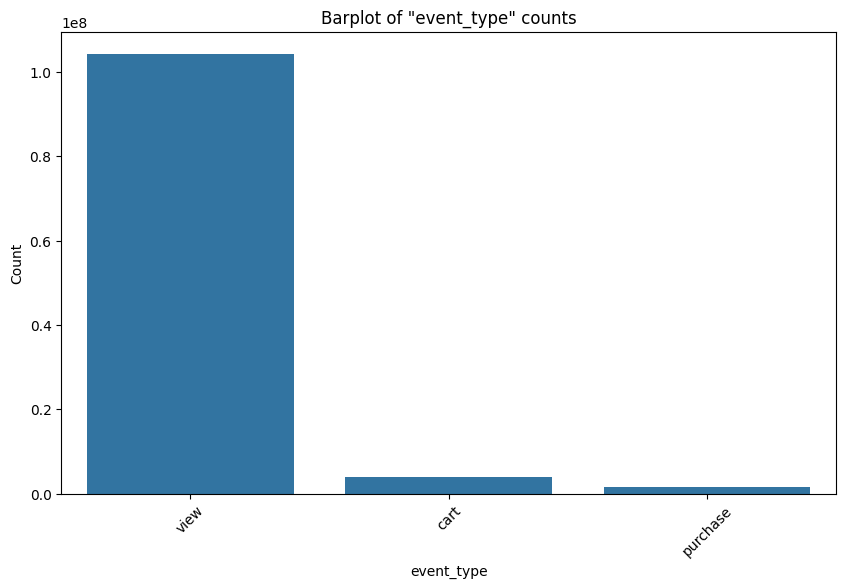

In [23]:
plot_cat_distribution(data=df, column_name="event_type")

Подавляющее число событий — просмотры товаров (`view`), что типично для событийных данных интернет-магазинов: на каждую покупку приходится большое число просмотров.

### Анализ временных признаков

Определим границы временного периода, охваченного датасетом.

In [24]:
df.select(
    min("event_time").alias("first_event"),
    max("event_time").alias("last_event")
).show()

+-------------------+-------------------+
|        first_event|         last_event|
+-------------------+-------------------+
|2019-10-01 00:00:00|2019-11-30 23:59:59|
+-------------------+-------------------+



Выведем статистические показатели производных количественных временных признаков.

In [25]:
df.select("hour", "day_of_week").summary(
    "count", "mean", "stddev", "min", "25%", "50%", "75%", "max"
).show()

+-------+------------------+------------------+
|summary|              hour|       day_of_week|
+-------+------------------+------------------+
|  count|         109950743|         109950743|
|   mean|11.259859990213982|  4.15796317993049|
| stddev|  5.31431549130376|2.0847048772789956|
|    min|                 0|                 1|
|    25%|                 7|                 2|
|    50%|                12|                 4|
|    75%|                16|                 6|
|    max|                23|                 7|
+-------+------------------+------------------+



Создадим функции визуализации: график динамики числа событий по дням и столбчатую диаграмму числа событий по значениям порядкового признака (час, день недели).

In [26]:
def plot_daily_timeline(data: DataFrame) -> None:
    """
    Построение графика динамики числа событий по датам.

    Args:
        data (DataFrame): DataFrame, содержащий данные.

    Returns:
        None
    """
    daily = (
        data
        .groupBy("event_date")
        .count()
        .orderBy("event_date")
        .toPandas()
    )
    daily["event_date"] = pd.to_datetime(daily["event_date"])

    plt.figure(figsize=(16, 5))
    sns.lineplot(data=daily, x="event_date", y="count")
    plt.title("Динамика числа событий по дням")
    plt.xlabel("Дата")
    plt.ylabel("Число событий")
    plt.grid(True)
    plt.show()

In [27]:
def plot_counts_bar(data: DataFrame,
                    column_name: str,
                    title: str,
                    figsize: tuple = (14, 5)) -> None:
    """
    Построение столбчатой диаграммы числа строк по значениям столбца
    с сортировкой по значению столбца (для порядковых признаков).

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        column_name (str): Имя столбца для группировки.
        title (str): Заголовок диаграммы.
        figsize (tuple): Размер фигуры.

    Returns:
        None
    """
    counts = (
        data
        .groupBy(column_name)
        .count()
        .orderBy(column_name)
        .toPandas()
    )

    plt.figure(figsize=figsize)
    sns.barplot(data=counts, x=column_name, y="count", color="steelblue")
    plt.title(title)
    plt.xlabel(column_name)
    plt.ylabel("Число событий")
    plt.grid(True, axis="y")
    plt.show()

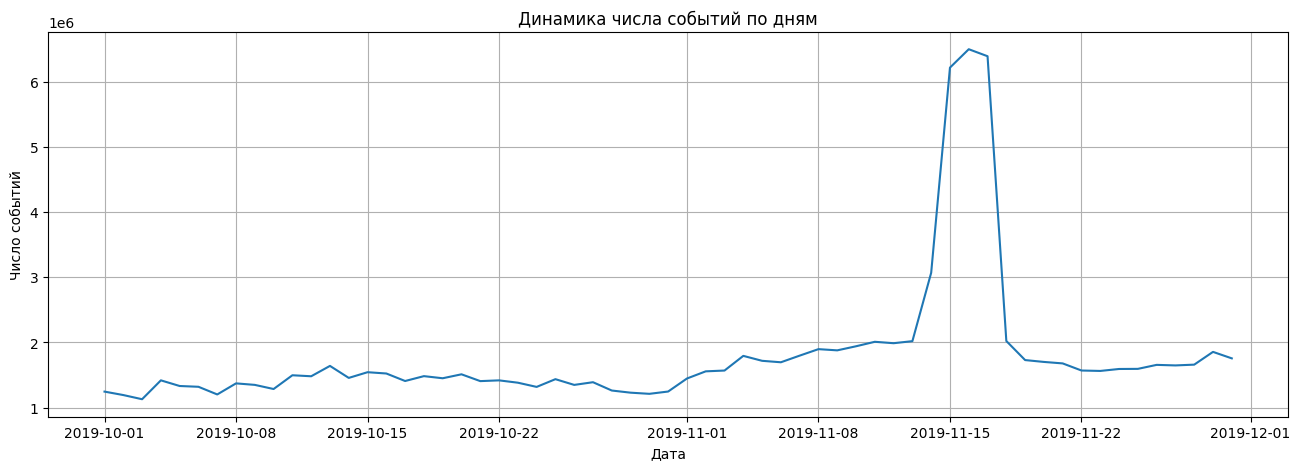

In [28]:
plot_daily_timeline(data=df)

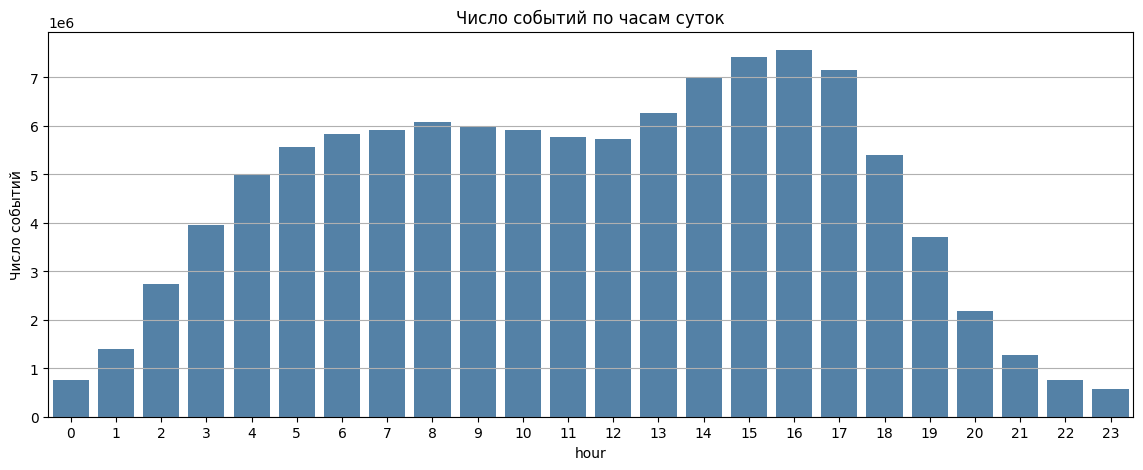

In [29]:
plot_counts_bar(data=df, column_name="hour", title="Число событий по часам суток")

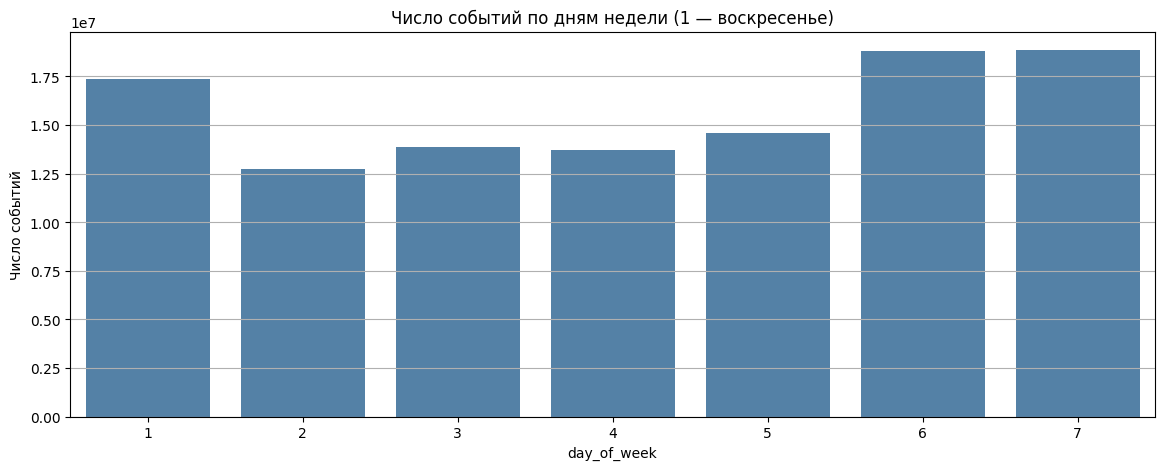

In [30]:
plot_counts_bar(data=df, column_name="day_of_week",
                  title="Число событий по дням недели (1 — воскресенье)")

Активность пользователей закономерно меняется в течение суток (минимум в ночные часы, максимум — вечером) и практически равномерно распределена по дням недели.

### Анализ признака `category_code`

Признак **категориальный**: код категории товара, имеющий иерархическую структуру (уровни разделяются точкой). Проверим пропуски и устраним их.

In [31]:
count_nulls(data=df, column_name="category_code")

Число колонок с NULL: 35413780 (32.21%)


In [32]:
df = df.withColumn(
    "category_code",
    coalesce(col("category_code"), lit("unknown"))
)

Сформируем признак `category_l1` — верхний уровень иерархии категории — и посмотрим на его распределение.

In [33]:
df = df.withColumn(
    "category_l1",
    element_at(split(col("category_code"), r"\."), 1)
)

Количество категорий признака category_l1: 14


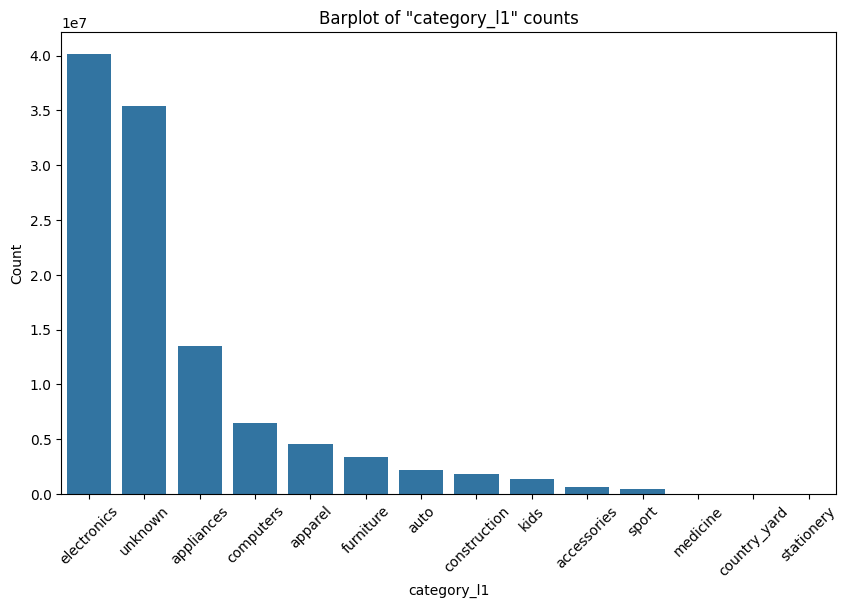

In [34]:
plot_cat_distribution(data=df, column_name="category_l1", top_n=15)

Наибольшее число событий относится к категориям `electronics`, `apparel` и `computers`, что соответствует профилю магазина.

### Анализ признака `brand`

Признак **категориальный**. Количество уникальных брендов в датасете велико, поэтому визуализируем только наиболее популярные из них.

In [35]:
count_nulls(data=df, column_name="brand")

Число колонок с NULL: 15331243 (13.94%)


In [36]:
df = df.fillna({"brand": "unknown"})

Количество категорий признака brand: 4304


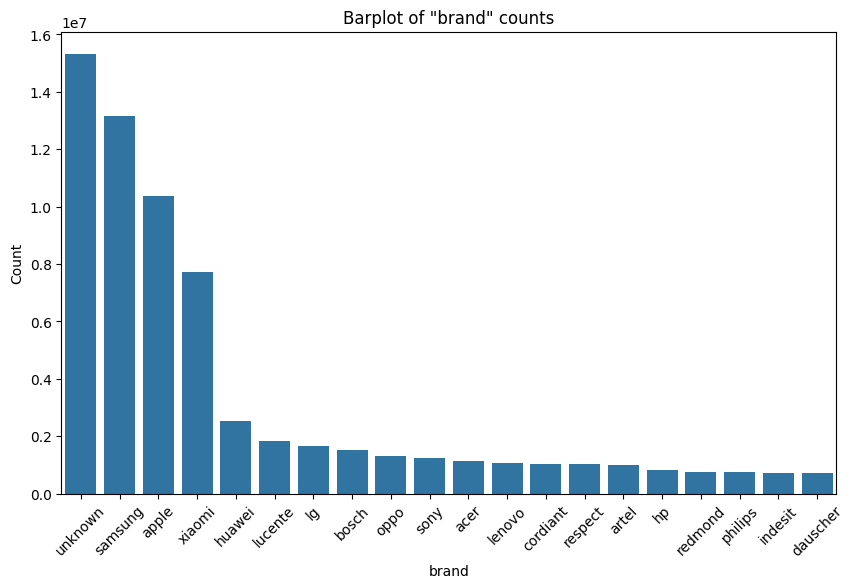

In [37]:
plot_cat_distribution(data=df, column_name="brand", top_n=20)

### Анализ признака `user_session`

Идентификатор пользовательской сессии. Пропусков мало — удалим соответствующие строки, чтобы все события были однозначно привязаны к сессии.

In [38]:
count_nulls(data=df, column_name="user_session")

Число колонок с NULL: 12 (0.00%)


In [39]:
df = df.filter(col("user_session").isNotNull())
df.count()

109950731

### Поиск и устранение дубликатов

Проверим наличие дубликатов событий. Ключом события будем считать набор столбцов `event_time`, `event_type`, `product_id`, `user_id`, `user_session`: совпадение всех этих значений означает, что одно и то же событие записано дважды.

In [40]:
event_key_columns = [
    "event_time", "event_type", "product_id", "user_id", "user_session"
]

duplicated_events = (
    df
    .groupBy(event_key_columns)
    .count()
    .where(col("count") > 1)
    .select(
        sum("count").alias("rows_in_dup_groups"),
        count("*").alias("dup_groups")
    )
    .collect()[0]
)

print(f"Число групп полных дубликатов: {duplicated_events['dup_groups'] or 0}")
print("Число избыточных строк: "
      f"{(duplicated_events['rows_in_dup_groups'] or 0) - (duplicated_events['dup_groups'] or 0)}")

Число групп полных дубликатов: 75657
Число избыточных строк: 130750


In [41]:
df = df.dropDuplicates(event_key_columns)
df.count()

109819981

### Анализ признака `price`

Признак **количественный** и является ключевым для бизнеса. Выведем его статистические показатели: количество, среднее, стандартное отклонение, минимум, квартили и максимум.

In [42]:
df.select("price").summary(
    "count", "mean", "stddev", "min", "25%", "50%", "75%", "max"
).show()

+-------+------------------+
|summary|             price|
+-------+------------------+
|  count|         109819981|
|   mean|291.64426751693816|
| stddev| 356.7289417812707|
|    min|               0.0|
|    25%|             67.96|
|    50%|            164.88|
|    75%|            360.11|
|    max|           2574.07|
+-------+------------------+



Среднее значение существенно превышает медиану, а максимум на несколько порядков больше типичных значений — распределение цены имеет ярко выраженный правосторонний «тяжелый хвост». 

Создадим функции, позволяющие рассчитывать статистические показатели, строить диаграмму «ящик с усами» для оценки выбросов и визуализировать распределение количественного признака (аналогично второй части работы).

In [43]:
def plot_boxplots(data: DataFrame,
                  columns: list[str],
                  sample_fraction: float = 0.1) -> None:
    """
    Построение boxplot для нескольких столбцов в PySpark DataFrame.

    Args:
        data (DataFrame): DataFrame, содержащий данные.
        columns (list of str): Список имен столбцов для построения boxplot.
        sample_fraction (float): Доля данных для семплирования выбросов.

    Returns:
        None
    """
    box_data = []

    for column in columns:
        # Вычисление квантилей
        quantiles = data.approxQuantile(column, [0.25, 0.5, 0.75], 0.01)
        q1, median, q3 = quantiles

        # Вычисление IQR и границ усов
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        # Фильтрация выбросов
        filtered_df = data.filter((col(column) >= lower_bound) & (col(column) <= upper_bound))
        outliers_df = data.filter((col(column) < lower_bound) | (col(column) > upper_bound))

        # Вычисление минимального и максимального значений
        min_value = data.agg({column: "min"}).collect()[0][0]
        mean_value = data.agg({column: "mean"}).collect()[0][0]
        std_value = data.agg({column: "std"}).collect()[0][0]
        max_value = data.agg({column: "max"}).collect()[0][0]

        # Ограничение усов минимальным и максимальным значениями
        lower_bound = max(lower_bound, min_value)
        upper_bound = min(upper_bound, max_value)

        # Семплирование выбросов
        outliers = []
        if not outliers_df.isEmpty():
            sampled_outliers_df = outliers_df.sample(sample_fraction)
            outliers = (
                sampled_outliers_df
                .select(column)
                .limit(1000)
                .collect()
            )
            outliers = [row[column] for row in outliers]

            # Добавление минимального и максимального значений, если они
            # относятся к выбросам и не присутствуют в семпле
            if min_value < lower_bound and min_value not in outliers:
                outliers.append(min_value)
            if max_value > upper_bound and max_value not in outliers:
                outliers.append(max_value)

        # Подготовка данных для axes.bxp
        box_data.append({
            'whislo': lower_bound,  # Нижняя граница усов
            'q1': q1,               # Первый квартиль
            'med': median,          # Медиана
            'q3': q3,               # Третий квартиль
            'whishi': upper_bound,  # Верхняя граница усов
            'fliers': outliers      # Выбросы
        })

    # Вывод статистических характеристик
    print(f"Минимальное значение:          {min_value:.2f}")
    print(f"Среднее значение:              {mean_value:.2f}")
    print(f"Среднеквадратичное отклонение: {std_value:.2f}")
    print(f"Первый квартиль:               {q1:.2f}")
    print(f"Медиана:                       {median:.2f}")
    print(f"Третий квартиль:               {q3:.2f}")
    print(f"Максимальное значение:         {max_value:.2f}")

    # Построение boxplot
    fig, ax = plt.subplots(figsize=(20, 6))
    ax.bxp(box_data,
           vert=False,
           positions=range(1, len(columns) + 1), widths=0.5)
    ax.set_yticks(range(1, len(columns) + 1))
    ax.set_yticklabels(columns)
    ax.set_xlabel('Value')
    ax.set_title('Boxplots')
    ax.grid(True)
    plt.show()

In [44]:
def plot_quant_distribution(data: DataFrame,
                            column: str,
                            num_bins: int = 200) -> None:
    """
    Построение гистограммы для количественной переменной с
    использованием PySpark и Seaborn.

    Args:
        data (DataFrame): DataFrame с данными.
        column_name (str): Название колонки с количественной переменной.
        num_bins (int): Количество бинов для гистограммы.

    Returns:
        None
    """
    # Находим минимальное и максимальное значения колонки
    min_value = data.agg({column: "min"}).collect()[0][0]
    max_value = data.agg({column: "max"}).collect()[0][0]

    # Размер бина
    bin_size = (max_value - min_value) / num_bins

    # Добавляем колонку с номером бина
    data = data.withColumn(
        "bin",
        floor((col(column) - min_value) / bin_size)
    )

    # Группируем по номеру бина и считаем количество строк в каждом бине
    bin_counts = data.groupBy("bin").count()

    # Преобразуем результат в Pandas DataFrame для построения гистограммы
    bin_counts_pd = bin_counts.limit(1000).toPandas()

    # Создаем массив границ бинов
    bin_edges = [min_value + i * bin_size for i in range(num_bins + 2)]

    # Преобразуем номера бинов в центры бинов
    bin_centers = [
        (bin_edges[i] + bin_edges[i + 1]) / 2 for i in range(num_bins + 1)
    ]

    # Добавляем центры бинов в Pandas DataFrame
    bin_counts_pd['bin_center'] = bin_counts_pd['bin'].apply(
        lambda x: bin_centers[int(x)]
    )

    # Построение гистограммы с использованием Seaborn
    plt.figure(figsize=(20, 6))
    sns.histplot(data=bin_counts_pd, x="bin_center",
                 weights="count", kde=True, bins=num_bins + 1)
    plt.xlabel("Value")
    plt.ylabel("Count")
    plt.title(f"Распределение количественного признака \"{column}\"")
    plt.grid(True)
    plt.show()

In [47]:
del min, max

Минимальное значение:          0.00
Среднее значение:              291.64
Среднеквадратичное отклонение: 356.73
Первый квартиль:               66.87
Медиана:                       163.71
Третий квартиль:               359.31
Максимальное значение:         2574.07


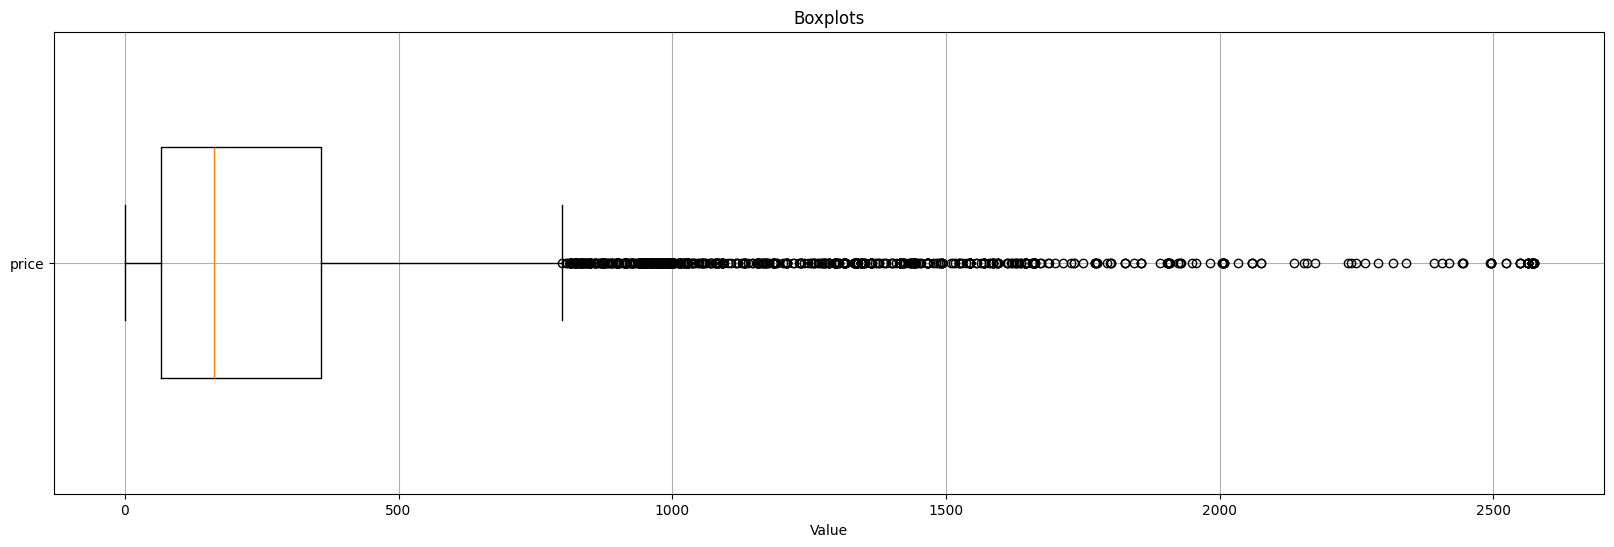

In [48]:
plot_boxplots(data=df, columns=["price"])

Диаграмма подтверждает наличие выбросов, причем двух принципиально разных типов:

1. **Неположительные цены** — явная ошибка данных: цена товара не может быть меньше или равна нулю.
2. **Экстремально большие цены** — законные, но редкие дорогие товары (например, электроника). Распределение цены имеет тяжелый правый хвост, поэтому строгая интерполяция по правилу «полтора межквартильных размаха» (`IQR`) непригодна: она отрезала бы значительную и полностью корректную часть ассортимора магазина.

В связи с этим примем следующую стратегию устранения выбросов: удалим события с неположительной ценой, а сверху ограничим признак **99-м перцентилем**.

In [49]:
negative_price_count = df.filter(col("price") <= 0).count()
negative_price_count

256657

In [50]:
q99 = df.approxQuantile("price", [0.99], 0.001)[0]
print(f"99-й перцентиль цены: {q99:.2f}")

99-й перцентиль цены: 1673.14


In [51]:
total_count = df.count()
outliers_count = df.filter((col("price") <= 0) | (col("price") > q99)).count()
print(f"Удаляется строк с выбросами: {outliers_count} "
      f"({100 * outliers_count / total_count:.2f}%)")

df = df.filter((col("price") > 0) & (col("price") <= q99))
df.count()

Удаляется строк с выбросами: 1386742 (1.26%)


108433239

Минимальное значение:          0.77
Среднее значение:              273.73
Среднеквадратичное отклонение: 306.82
Первый квартиль:               66.93
Медиана:                       161.91
Третий квартиль:               347.24
Максимальное значение:         1673.14


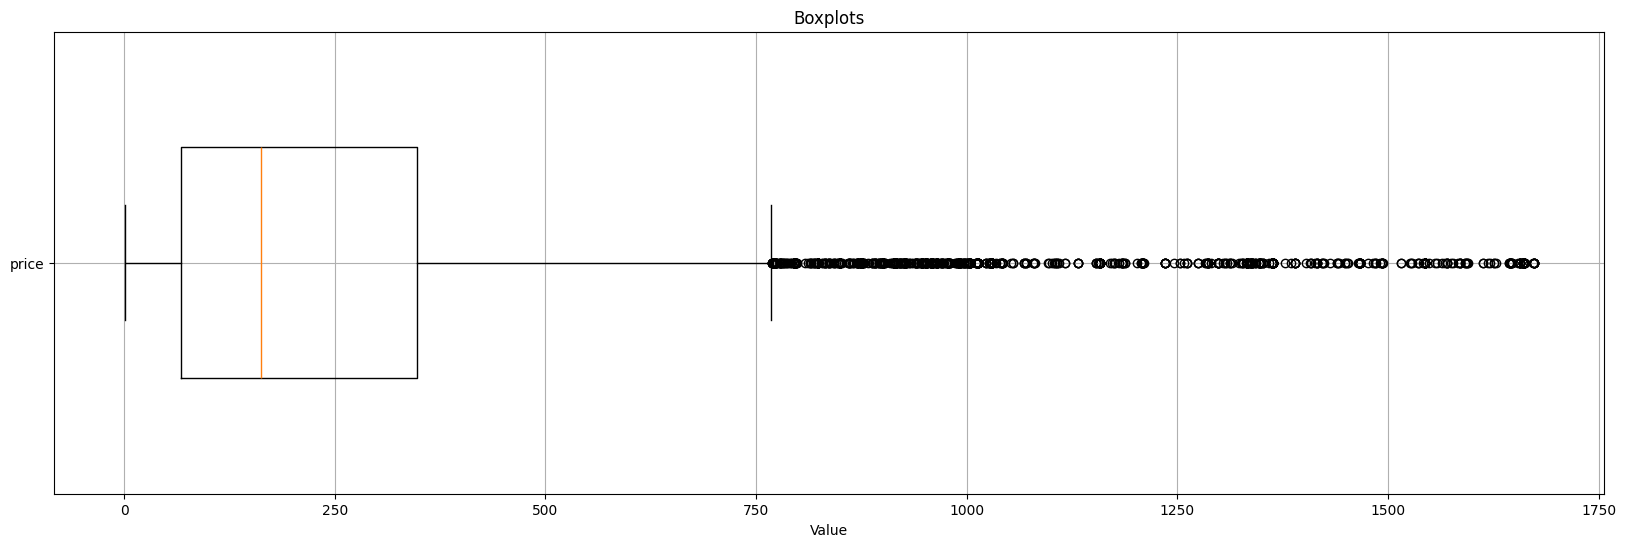

In [52]:
plot_boxplots(data=df, columns=["price"])

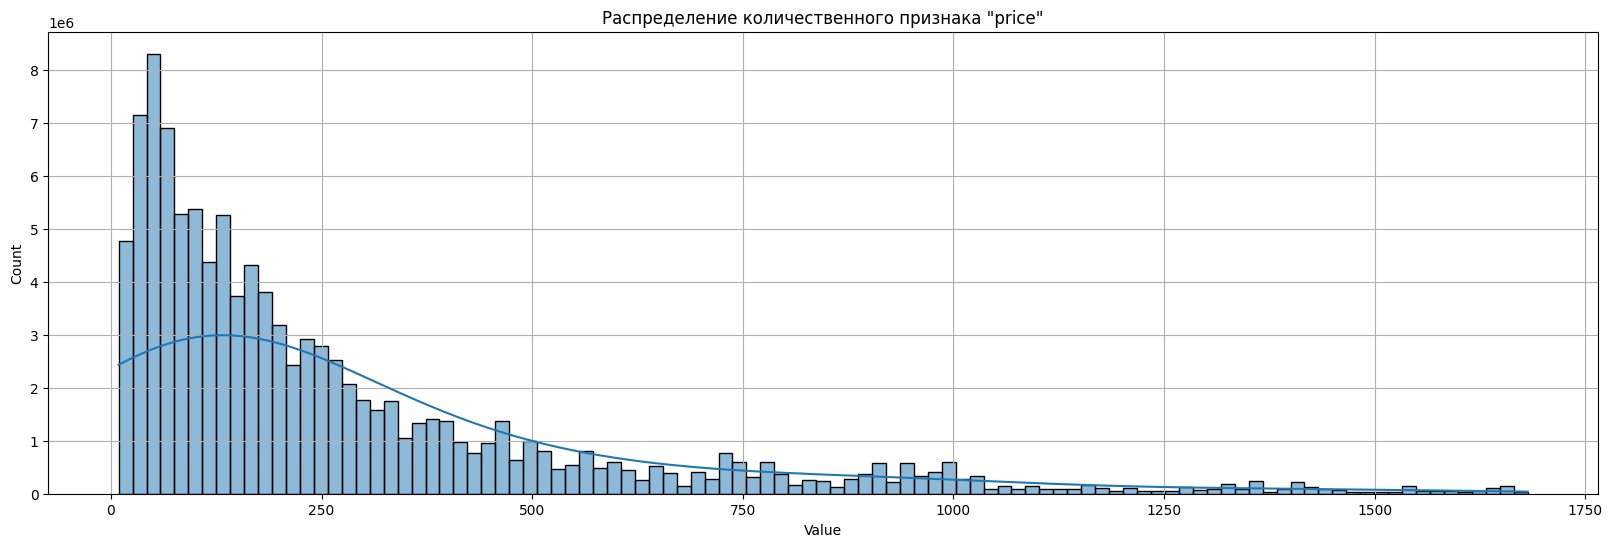

In [53]:
plot_quant_distribution(data=df, column="price", num_bins=100)

### Производные количественные признаки и корреляционный анализ

В исходном датасете лишь один «естественный» количественный признак — `price`. Для расчета корреляций дополним его производными признаками:

* `hour`, `day_of_week` — уже введенные временные признаки;
* `user_activity` — общее число событий, совершенных пользователем (активность пользователя);
* `product_popularity` — общее число событий, связанных с товаром (популярность товара).

Последние два признака рассчитаем с помощью оконных функций.

In [54]:
user_window = Window.partitionBy("user_id")
product_window = Window.partitionBy("product_id")

df = (
    df
    .withColumn("user_activity", count(lit(1)).over(user_window))
    .withColumn("product_popularity", count(lit(1)).over(product_window))
    .cache()
)

df.show(5, truncate=False)

+-------------------+----------+----------+-------------------+----------------------+---------+-----+---------+------------------------------------+----------+----+-----------+----------------+-----------+-------------+------------------+
|event_time         |event_type|product_id|category_id        |category_code         |brand    |price|user_id  |user_session                        |event_date|hour|day_of_week|day_of_week_name|category_l1|user_activity|product_popularity|
+-------------------+----------+----------+-------------------+----------------------+---------+-----+---------+------------------------------------+----------+----+-----------+----------------+-----------+-------------+------------------+
|2019-10-17 13:08:12|view      |1004223   |2053013555631882655|electronics.smartphone|prestigio|71.82|537181210|b111a815-70e4-47c1-bd97-19f988d559c2|2019-10-17|13  |5          |Thu             |electronics|277          |1350              |
|2019-10-26 08:40:23|view      |1004223 

Создадим функцию вычисления и визуализации корреляционной матрицы.

In [55]:
def compute_and_visualize_correlation_matrix(data: DataFrame,
                                             columns: list[str]) -> None:
    """
    Вычисляет и визуализирует корреляционную матрицу для указанных
    колонок в DataFrame PySpark.

    Args:
        df (DataFrame): DataFrame PySpark.
        columns (list[str]): Список колонок для вычисления корреляции.

    Returns:
        None
    """
    # Вычисление корреляционной матрицы
    corr_matrix = {}
    for col1 in columns:
        corr_matrix[col1] = {}
        for col2 in columns:
            corr_value = data.select(corr(col1, col2)).collect()[0][0]
            corr_matrix[col1][col2] = corr_value

    # Преобразование корреляционной матрицы в DataFrame Pandas для визуализации
    corr_matrix_pd = pd.DataFrame(corr_matrix)

    # Построение и визуализация корреляционной матрицы
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix_pd, annot=True, cmap='coolwarm', linewidths=0.5)
    plt.title('Correlation Matrix')
    plt.show()

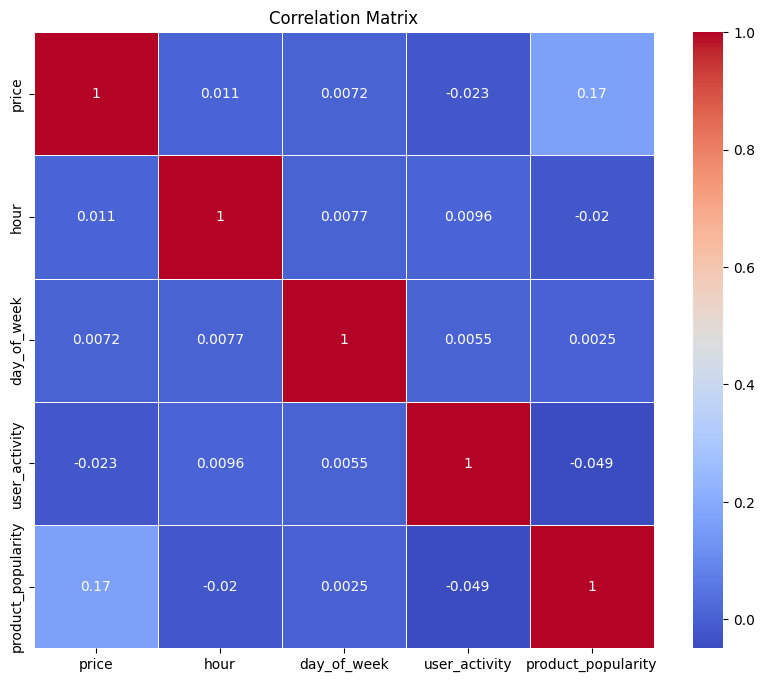

In [56]:
compute_and_visualize_correlation_matrix(
    data=df, columns=[
        "price", "hour", "day_of_week",
        "user_activity", "product_popularity"
    ]
)

Как видно из корреляционной матрицы, линейные связи между количественными признаками выражены слабо. Это ожидаемо для событийных данных электронной коммерции: цена товара практически не зависит от времени суток, а активность пользователей и популярность товаров определяются главным образом категориальными характеристиками (категорией, брендом), а не количественными. Подобные зависимости эффективнее исследовать с помощью группировок, что выполнено ниже.

### Дополнительные визуализации важных признаков

Сравним категории товаров по числу событий и средней цене.

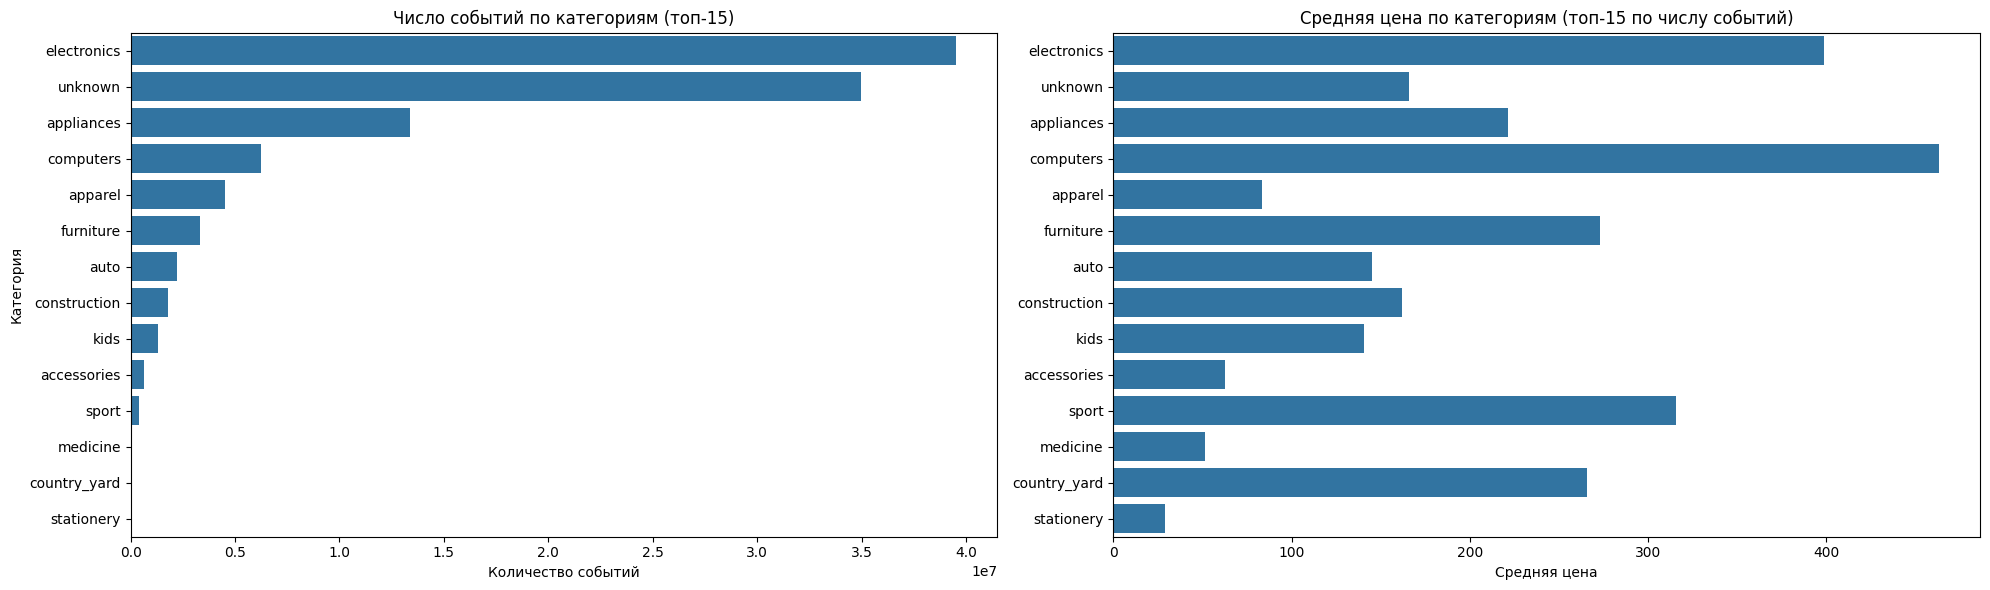

In [57]:
top_categories = (
    df
    .groupBy("category_l1")
    .agg(
        count("*").alias("events"),
        mean("price").alias("avg_price")
    )
    .orderBy(desc("events"))
    .limit(15)
    .toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
sns.barplot(data=top_categories, y="category_l1", x="events", ax=axes[0])
axes[0].set_title("Число событий по категориям (топ-15)")
axes[0].set_xlabel("Количество событий")
axes[0].set_ylabel("Категория")
sns.barplot(data=top_categories, y="category_l1", x="avg_price", ax=axes[1])
axes[1].set_title("Средняя цена по категориям (топ-15 по числу событий)")
axes[1].set_xlabel("Средняя цена")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

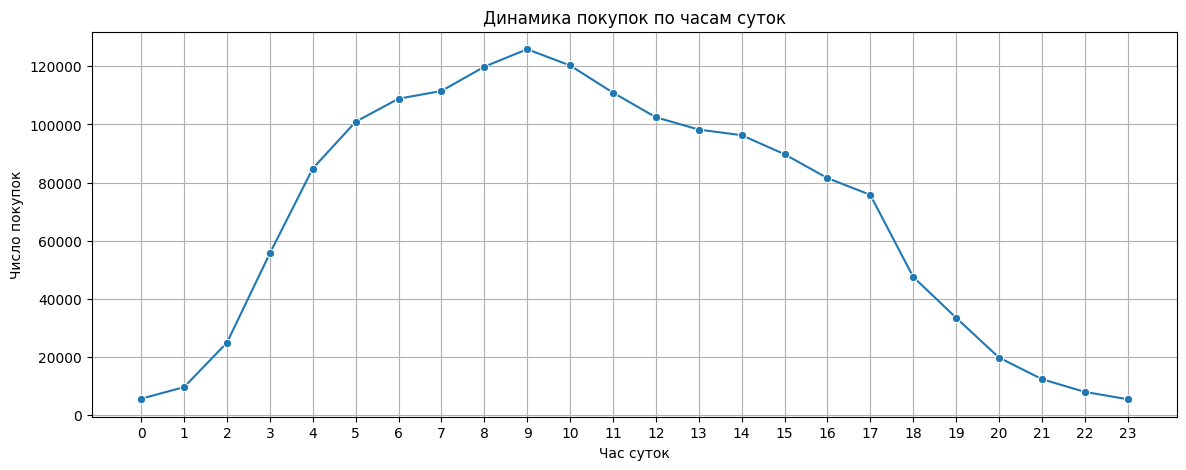

In [58]:
purchases_by_hour = (
    df
    .filter(col("event_type") == "purchase")
    .groupBy("hour")
    .count()
    .orderBy("hour")
    .toPandas()
)

plt.figure(figsize=(14, 5))
sns.lineplot(data=purchases_by_hour, x="hour", y="count", marker="o")
plt.title("Динамика покупок по часам суток")
plt.xlabel("Час суток")
plt.ylabel("Число покупок")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

### Итоги преобразований

Посмотрим, сколько объектов осталось после всех преобразований датасета, и убедимся в корректности итоговой схемы.

In [59]:
df.count()

108433239

In [60]:
df.printSchema()

root
 |-- event_time: timestamp (nullable = true)
 |-- event_type: string (nullable = true)
 |-- product_id: long (nullable = true)
 |-- category_id: long (nullable = true)
 |-- category_code: string (nullable = false)
 |-- brand: string (nullable = false)
 |-- price: double (nullable = true)
 |-- user_id: long (nullable = true)
 |-- user_session: string (nullable = true)
 |-- event_date: date (nullable = true)
 |-- hour: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)
 |-- day_of_week_name: string (nullable = true)
 |-- category_l1: string (nullable = true)
 |-- user_activity: long (nullable = false)
 |-- product_popularity: long (nullable = false)



Сохраняем очищенную и обработанную таблицу на диск.

In [61]:
df.writeTo(table_processed_name).using("iceberg").create()

In [62]:
for table in spark.catalog.listTables():
    print(table.name)

korolev_lab1_events_processed
korolev_lab1_events_raw


Обратите внимание, что при необходимости созданные базу данных и таблицы можно удалить следующими командами.

In [63]:
# spark.sql(f"DROP TABLE spark_catalog.{database_name}.{table_processed_name}")
# spark.sql(f"DROP TABLE spark_catalog.{database_name}.{table_raw_name}")
# spark.sql(f"DROP DATABASE spark_catalog.{database_name}")

### Выводы

В ходе выполнения разведочного анализа датасета `«eCommerce behavior data from multi category store»` объемом более 10 ГБ (свыше 100 млн событий) с использованием фреймворка `Apache Spark`:

* определены типы всех признаков датасета (временные, категориальные, количественные, идентификаторы) и выполнено приведение типов при загрузке данных из `CSV`;
* выявлены и устранены пропущенные значения: пропуски в `category_code` (около трети строк) и `brand` (порядка 15% строк) заменены категорией `unknown`, строки с пропуском `user_session` удалены;
* проверено наличие дубликатов событий, полные дубликаты удалены;
* выявлены и устранены выбросы признака `price`: события с неположительной ценой и ценой выше 99-го перцентиля признаны аномальными и удалены (составили около одного процента данных);
* рассчитаны статистические показатели количественных признаков (минимум, среднее, стандартное отклонение, квартили, максимум);
* построены визуализации распределений важнейших признаков: типов событий, категорий и брендов товаров, цены, а также временной динамики числа событий и покупок;
* рассчитана корреляционная матрица количественных признаков (`price`, `hour`, `day_of_week`, `user_activity`, `product_popularity`); линейные связи оказались слабыми, что типично для событийных данных.

Очищенный датафрейм сохранен в таблицы `Apache Iceberg` и может использоваться в дальнейших исследованиях (например, при построении рекомендательных систем или прогнозировании покупок).

Выполнение анализа подобных объемов данных (~10 ГБ, более 100 млн строк) средствами `pandas` на одном компьютере нерационально. Распределенные вычисления `Apache Spark` на кластере `YARN` с данными в `HDFS` позволили выполнить все этапы анализа без загрузки данных в память одного узла.

Останавливаем `Spark`-сессию.

In [64]:
spark.stop()